In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import joblib


In [33]:
df = pd.read_excel('default_of_credit_card_clients.xls', header = 1)

print('Wymiary zbioru:', df.shape)
df.head()

Wymiary zbioru: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [34]:
df.info()

print('Missing values:', df.isnull().sum().sum())

print('Duplicated values:', df.duplicated().sum())

print('Duplicated IDs:', df['ID'].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_AMT3        

In [35]:
df.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [36]:
categorical_columns = ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

for column in categorical_columns:
    print(f'\n{column}:')
    print(df[column].value_counts().sort_index())


SEX:
SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

PAY_0:
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

PAY_2:
PAY_2
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1
Name: count, dtype: int64

PAY_3:
PAY_3
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3
Name: count, dtype: int64

PAY_4:
PAY_4
-2     4348
-1     5687
 0    16455
 1        2
 2     3159
 3      180
 4       69
 5       35
 6        5
 7       58
 8        2
Name: count, dtype: int64

PAY_5:
PAY_5
-2     4546
-1     5539
 

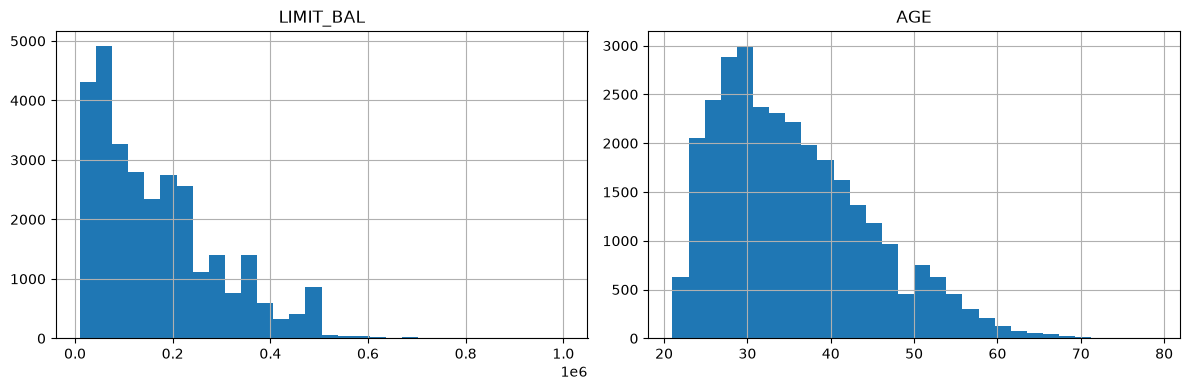

In [37]:
df[['LIMIT_BAL', 'AGE']].hist(figsize=(12, 4), bins=30)
plt.tight_layout()
plt.show()

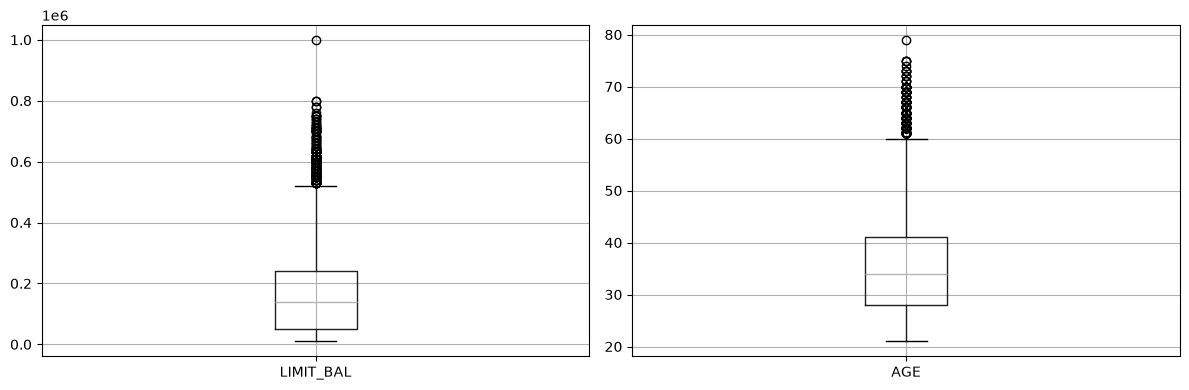

In [38]:
fig, axes = plt.subplots(1, 2, figsize = (12, 4))

df.boxplot(column = 'LIMIT_BAL', ax = axes[0])
df.boxplot(column = 'AGE', ax = axes[1])

plt.tight_layout()
plt.show()

In [39]:
financial_columns = [f'BILL_AMT{i}' for i in range(1, 7)] + [f'PAY_AMT{i}' for i in range(1, 7)]

df[financial_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
BILL_AMT1,30000.0,51223.330900,73635.860576,-165580.0,3558.75,22381.5,67091.00,964511.0
BILL_AMT2,30000.0,49179.075167,71173.768783,-69777.0,2984.75,21200.0,64006.25,983931.0
BILL_AMT3,30000.0,47013.154800,69349.387427,-157264.0,2666.25,20088.5,60164.75,1664089.0
BILL_AMT4,30000.0,43262.948967,64332.856134,-170000.0,2326.75,19052.0,54506.00,891586.0
BILL_AMT5,30000.0,40311.400967,60797.155770,-81334.0,1763.00,18104.5,50190.50,927171.0
BILL_AMT6,30000.0,38871.760400,59554.107537,-339603.0,1256.00,17071.0,49198.25,961664.0
PAY_AMT1,30000.0,5663.580500,16563.280354,0.0,1000.00,2100.0,5006.00,873552.0
PAY_AMT2,30000.0,5921.163500,23040.870402,0.0,833.00,2009.0,5000.00,1684259.0
PAY_AMT3,30000.0,5225.681500,17606.961470,0.0,390.00,1800.0,4505.00,896040.0
PAY_AMT4,30000.0,4826.076867,15666.159744,0.0,296.00,1500.0,4013.25,621000.0


In [40]:
financial_summary = pd.DataFrame({
    'Negative values': (df[financial_columns] < 0).sum(),
    'Zero values': (df[financial_columns] == 0).sum(),
    'Positive values': (df[financial_columns] > 0).sum()
})

financial_summary

,Negative values,Zero values,Positive values
BILL_AMT1,590,2008,27402
BILL_AMT2,669,2506,26825
BILL_AMT3,655,2870,26475
BILL_AMT4,675,3195,26130
BILL_AMT5,655,3506,25839
BILL_AMT6,688,4020,25292
PAY_AMT1,0,5249,24751
PAY_AMT2,0,5396,24604
PAY_AMT3,0,5968,24032
PAY_AMT4,0,6408,23592


default payment next month
0    23364
1     6636
Name: count, dtype: int64

Percentage distribution:
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64


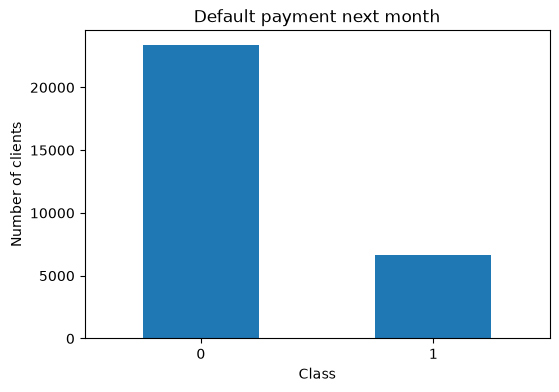

In [41]:
target = 'default payment next month'

print(df[target].value_counts())
print('\nPercentage distribution:')
print(df[target].value_counts(normalize = True) * 100)

df[target].value_counts().sort_index().plot(kind = 'bar', figsize = (6, 4))

plt.title('Default payment next month')
plt.xlabel('Class')
plt.ylabel('Number of clients')
plt.xticks(rotation = 0)
plt.show()

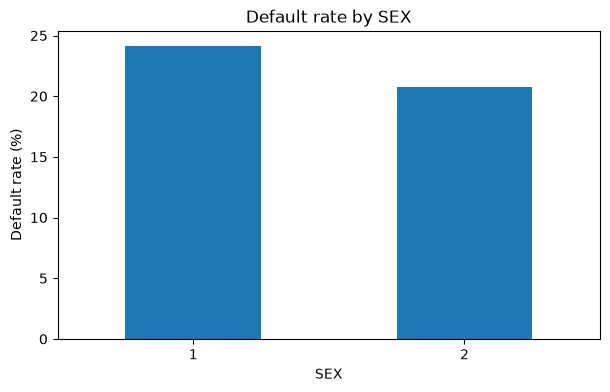

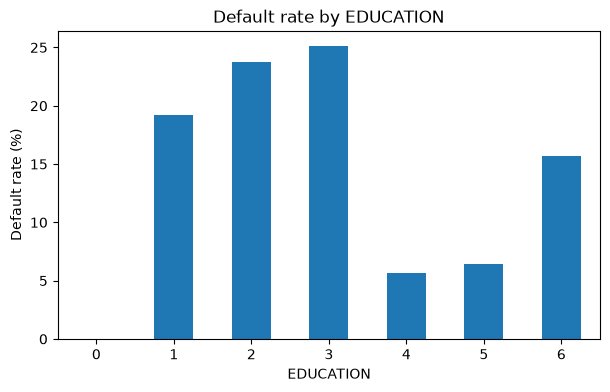

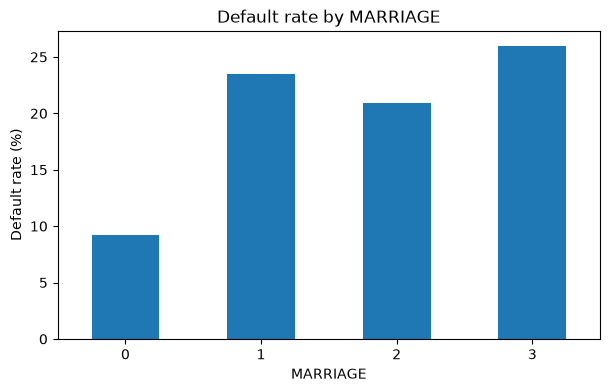

In [42]:
for column in ['SEX', 'EDUCATION', 'MARRIAGE']:
    default_rate = df.groupby(column)[target].mean() * 100

    default_rate.plot(kind = 'bar', figsize = (7, 4))
    plt.title(f'Default rate by {column}')
    plt.xlabel(column)
    plt.ylabel('Default rate (%)')
    plt.xticks(rotation = 0)
    plt.show()

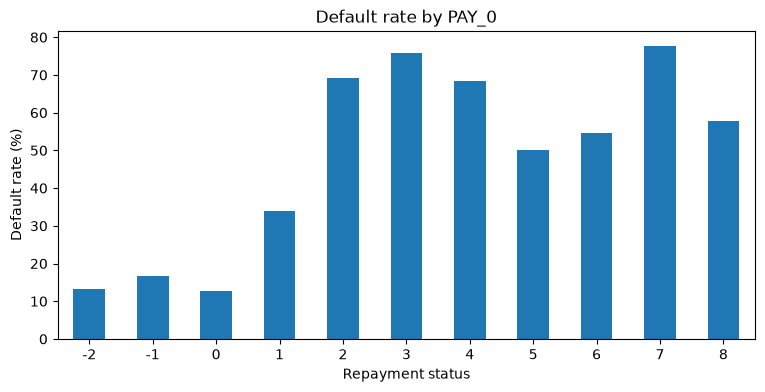

In [43]:
default_rate = df.groupby('PAY_0')[target].mean() * 100

default_rate.plot(kind = 'bar', figsize = (9, 4))

plt.title('Default rate by PAY_0')
plt.xlabel('Repayment status')
plt.ylabel('Default rate (%)')
plt.xticks(rotation = 0)
plt.show()

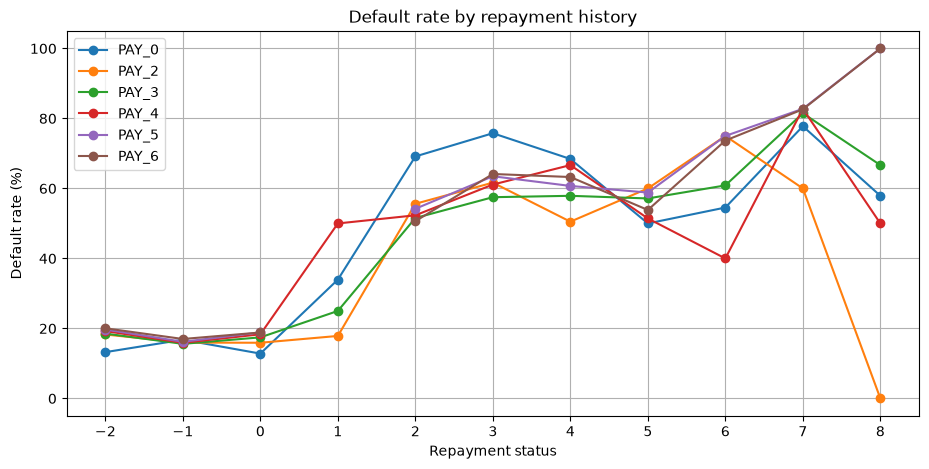

In [44]:
payment_columns = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

payment_default_rates = pd.DataFrame({
    column: df.groupby(column)[target].mean() * 100 for column in payment_columns
})

payment_default_rates.plot(figsize = (11, 5), marker = 'o')

plt.title('Default rate by repayment history')
plt.xlabel('Repayment status')
plt.ylabel('Default rate (%)')
plt.xticks(payment_default_rates.index)
plt.grid(True)
plt.show()

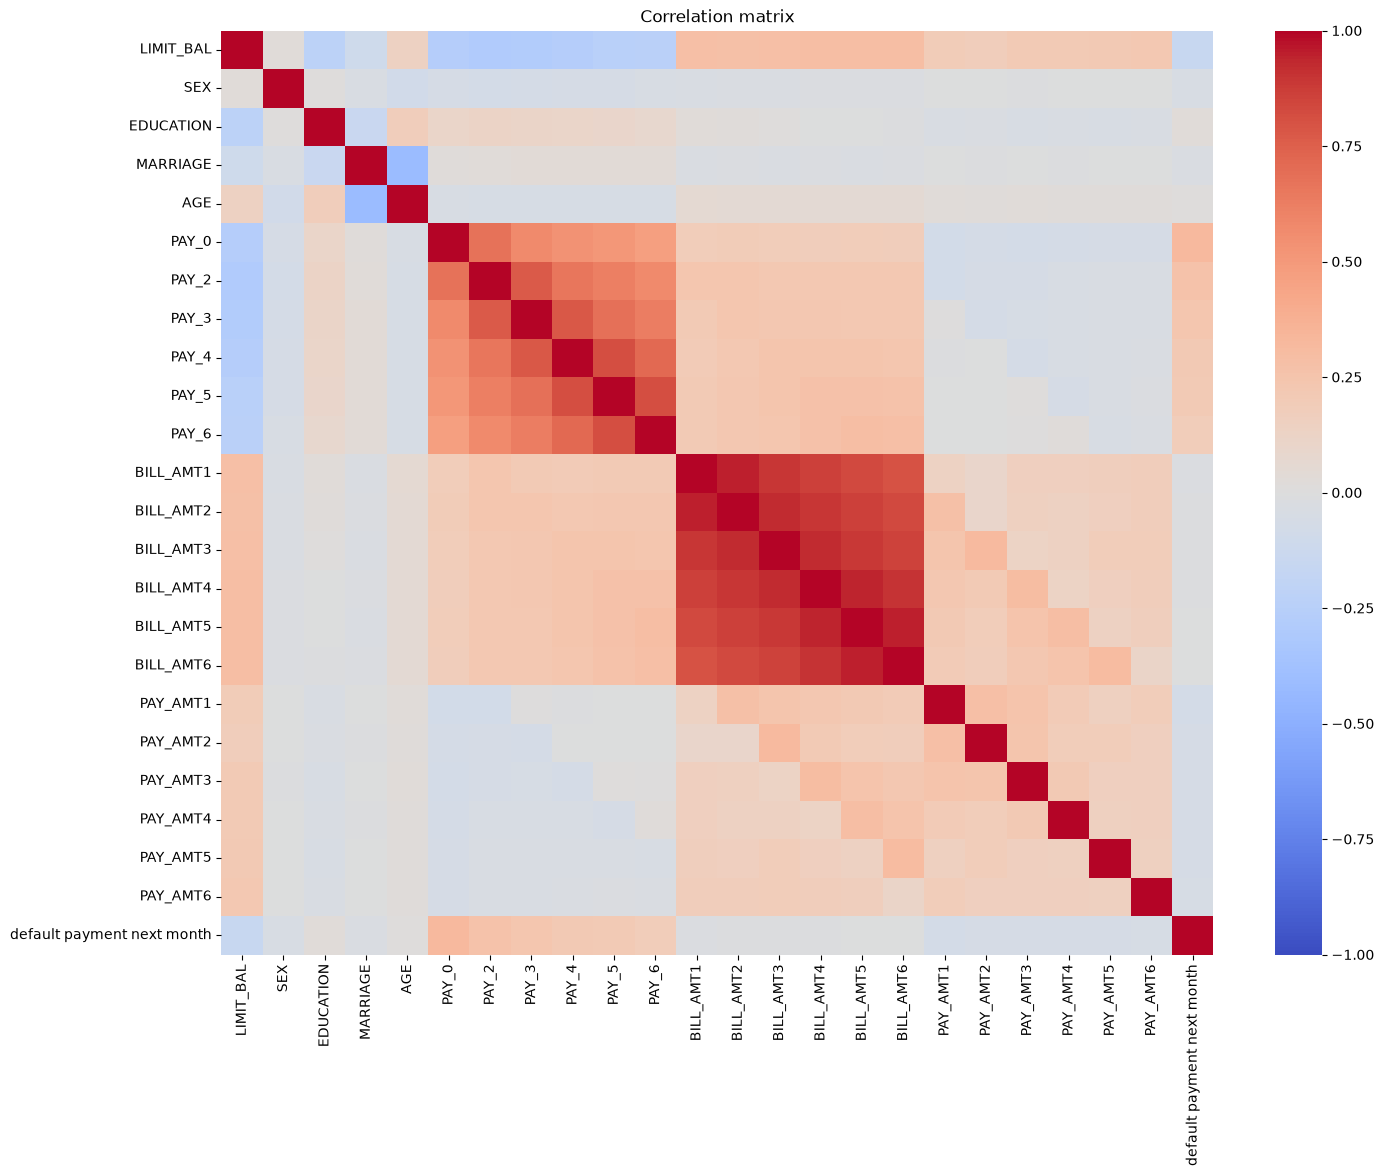

In [45]:
correlation = df.drop(columns = 'ID').corr()

plt.figure(figsize = (16, 12))
sns.heatmap(correlation, cmap = 'coolwarm', center = 0, vmin = -1, vmax = 1)
plt.title('Correlation matrix')
plt.show()

In [46]:
correlation[target].drop(target).sort_values(ascending = False)

PAY_0        0.324794
PAY_2        0.263551
PAY_3        0.235253
PAY_4        0.216614
PAY_5        0.204149
PAY_6        0.186866
EDUCATION    0.028006
AGE          0.013890
BILL_AMT6   -0.005372
BILL_AMT5   -0.006760
BILL_AMT4   -0.010156
BILL_AMT3   -0.014076
BILL_AMT2   -0.014193
BILL_AMT1   -0.019644
MARRIAGE    -0.024339
SEX         -0.039961
PAY_AMT6    -0.053183
PAY_AMT5    -0.055124
PAY_AMT3    -0.056250
PAY_AMT4    -0.056827
PAY_AMT2    -0.058579
PAY_AMT1    -0.072929
LIMIT_BAL   -0.153520
Name: default payment next month, dtype: float64

In [47]:
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})
df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})

print(df['EDUCATION'].value_counts().sort_index())
print()
print(df['MARRIAGE'].value_counts().sort_index())

EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64

MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


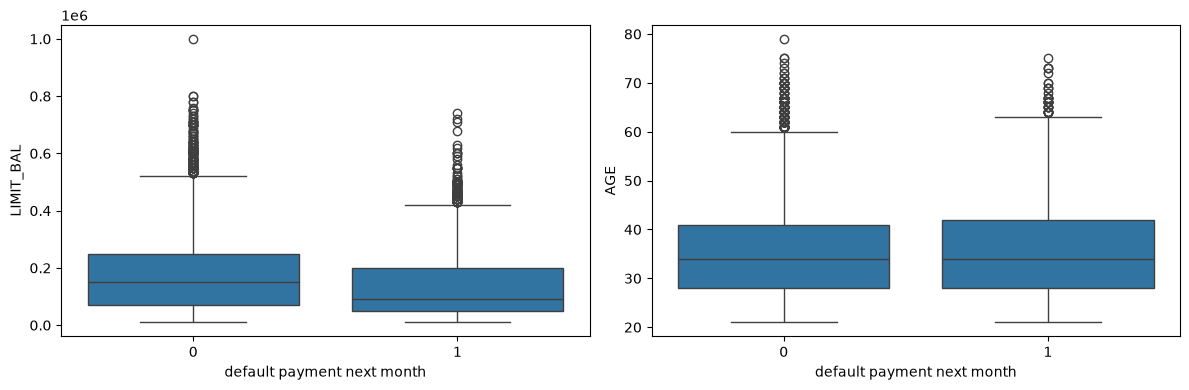

In [48]:
fig, axes = plt.subplots(1, 2, figsize = (12, 4))

sns.boxplot(data = df, x = target, y = 'LIMIT_BAL', ax = axes[0])
sns.boxplot(data = df, x = target, y = 'AGE', ax = axes[1])

plt.tight_layout()
plt.show()

In [49]:
X = df.drop(columns = ['ID', target])
y = df[target]

print('X:', X.shape)
print('y:', y.shape)

X: (30000, 23)
y: (30000,)


In [79]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

print('\nTrain class distribution:')
print(y_train.value_counts(normalize = True) * 100)

print('\nTest class distribution:')
print(y_test.value_counts(normalize = True) * 100)

X_train: (24000, 23)
X_test: (6000, 23)
y_train: (24000,)
y_test: (6000,)

Train class distribution:
default payment next month
0    77.879167
1    22.120833
Name: proportion, dtype: float64

Test class distribution:
default payment next month
0    77.883333
1    22.116667
Name: proportion, dtype: float64


In [80]:
baseline = DummyClassifier(strategy = 'most_frequent')
baseline.fit(X_train, y_train)

y_pred_baseline = baseline.predict(X_test)

print('Accuracy:', accuracy_score(y_test, y_pred_baseline))
print('Precision:', precision_score(y_test, y_pred_baseline, zero_division = 0))
print('Recall:', recall_score(y_test, y_pred_baseline))
print('F1:', f1_score(y_test, y_pred_baseline))
print('\nConfusion matrix:')
print(confusion_matrix(y_test, y_pred_baseline))

Accuracy: 0.7788333333333334
Precision: 0.0
Recall: 0.0
F1: 0.0

Confusion matrix:
[[4673    0]
 [1327    0]]


In [81]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(random_state = 42)
decision_tree.fit(X_train, y_train)

y_pred_tree = decision_tree.predict(X_test)

print('Accuracy:', accuracy_score(y_test, y_pred_tree))
print('Precision:', precision_score(y_test, y_pred_tree))
print('Recall:', recall_score(y_test, y_pred_tree))
print('F1:', f1_score(y_test, y_pred_tree))

print('\nConfusion matrix:')
print(confusion_matrix(y_test, y_pred_tree))

Accuracy: 0.7195
Precision: 0.3765603328710125
Recall: 0.4091936699321778
F1: 0.39219934994582883

Confusion matrix:
[[3774  899]
 [ 784  543]]


In [82]:
y_pred_tree_train = decision_tree.predict(X_train)

print('Train accuracy:', accuracy_score(y_train, y_pred_tree_train))
print('Test accuracy:', accuracy_score(y_test, y_pred_tree))

print('Train F1:', f1_score(y_train, y_pred_tree_train))
print('Test F1:', f1_score(y_test, y_pred_tree))

print('Tree depth:', decision_tree.get_depth())
print('Number of leaves:', decision_tree.get_n_leaves())

Train accuracy: 0.9994583333333333
Test accuracy: 0.7195
Train F1: 0.9987743942679362
Test F1: 0.39219934994582883
Tree depth: 40
Number of leaves: 3807


In [83]:
params_tree = {'max_depth': [3, 7, 13, 20, 40], 'min_samples_leaf': [1, 5, 10, 30, 100]}

cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

tree_gridsearch = GridSearchCV(DecisionTreeClassifier(random_state = 42), params_tree, scoring = 'f1', cv = cv, n_jobs = -1)

tree_gridsearch.fit(X_train, y_train)

print('Best hyperparams::', tree_gridsearch.best_params_)
print('Best F1 CV:', tree_gridsearch.best_score_)

Best hyperparams:: {'max_depth': 3, 'min_samples_leaf': 30}
Best F1 CV: 0.4843985757566398


In [84]:
best_tree = tree_gridsearch.best_estimator_

y_pred_tree_train = best_tree.predict(X_train)
y_pred_tree_test = best_tree.predict(X_test)

print('Train accuracy:', accuracy_score(y_train, y_pred_tree_train))
print('Test accuracy:', accuracy_score(y_test, y_pred_tree_test))

print('Train F1:', f1_score(y_train, y_pred_tree_train))
print('Test F1:', f1_score(y_test, y_pred_tree_test))

print('Test precision:', precision_score(y_test, y_pred_tree_test))
print('Test recall:', recall_score(y_test, y_pred_tree_test))

print('\nConfusion matrix:')
print(confusion_matrix(y_test, y_pred_tree_test))

Train accuracy: 0.8226666666666667
Test accuracy: 0.8181666666666667
Train F1: 0.4847457627118644
Test F1: 0.47269212179797004
Test precision: 0.6590296495956873
Test recall: 0.36850037678975134

Confusion matrix:
[[4420  253]
 [ 838  489]]


In [89]:
random_forest = RandomForestClassifier(random_state = 42, n_jobs = -1)
random_forest.fit(X_train, y_train)

y_pred_forest_train = random_forest.predict(X_train)
y_pred_forest_test = random_forest.predict(X_test)

print('Train accuracy:', accuracy_score(y_train, y_pred_forest_train))
print('Test accuracy:', accuracy_score(y_test, y_pred_forest_test))

print('Train F1:', f1_score(y_train, y_pred_forest_train))
print('Test F1:', f1_score(y_test, y_pred_forest_test))

print('Test precision:', precision_score(y_test, y_pred_forest_test))
print('Test recall:', recall_score(y_test, y_pred_forest_test))

print('\nConfusion matrix:')
print(confusion_matrix(y_test, y_pred_forest_test))

Train accuracy: 0.9994583333333333
Test accuracy: 0.8141666666666667
Train F1: 0.9987753179463024
Test F1: 0.4610923151280812
Test precision: 0.6428571428571429
Test recall: 0.359457422758101

Confusion matrix:
[[4408  265]
 [ 850  477]]


In [92]:
params_forest = {'n_estimators': [50, 100, 200], 'max_depth': [3, 7, 13, 20, 40], 'min_samples_leaf': [1, 5, 10, 30, 100]}

forest_gridsearch = GridSearchCV(RandomForestClassifier(random_state = 42, n_jobs = 1), params_forest, scoring = 'f1', cv = cv, n_jobs = -1)

forest_gridsearch.fit(X_train, y_train)

print('Best hyperparams::', forest_gridsearch.best_params_)
print('Best F1 CV:', forest_gridsearch.best_score_)

Best hyperparams:: {'max_depth': 40, 'min_samples_leaf': 1, 'n_estimators': 200}
Best F1 CV: 0.4767788834837746


In [93]:
best_forest = forest_gridsearch.best_estimator_

y_pred_forest_train = best_forest.predict(X_train)
y_pred_forest_test = best_forest.predict(X_test)

print('Train accuracy:', accuracy_score(y_train, y_pred_forest_train))
print('Test accuracy:', accuracy_score(y_test, y_pred_forest_test))

print('Train F1:', f1_score(y_train, y_pred_forest_train))
print('Test F1:', f1_score(y_test, y_pred_forest_test))

print('Test precision:', precision_score(y_test, y_pred_forest_test))
print('Test recall:', recall_score(y_test, y_pred_forest_test))

print('\nConfusion matrix:')
print(confusion_matrix(y_test, y_pred_forest_test))

Train accuracy: 0.9994583333333333
Test accuracy: 0.8121666666666667
Train F1: 0.9987748562812176
Test F1: 0.4594724220623501
Test precision: 0.6319261213720316
Test recall: 0.36096458176337604

Confusion matrix:
[[4394  279]
 [ 848  479]]


In [94]:
feature_importance = pd.Series(best_forest.feature_importances_, index = X_train.columns).sort_values(ascending = False)

print(feature_importance)

PAY_0        0.103376
AGE          0.066613
BILL_AMT1    0.059983
LIMIT_BAL    0.059965
BILL_AMT2    0.054045
BILL_AMT3    0.051355
BILL_AMT6    0.050923
PAY_AMT1     0.050342
BILL_AMT4    0.050251
BILL_AMT5    0.049900
PAY_AMT2     0.048262
PAY_AMT6     0.046286
PAY_AMT3     0.046278
PAY_AMT5     0.043369
PAY_AMT4     0.042762
PAY_2        0.039046
PAY_4        0.026008
PAY_3        0.024605
PAY_6        0.021801
EDUCATION    0.019955
PAY_5        0.019157
MARRIAGE     0.013427
SEX          0.012291
dtype: float64


In [95]:
selected_features = feature_importance.head(10).index

X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

print('Wybrane cechy:', selected_features.tolist())
print('X_train:', X_train_selected.shape)
print('X_test:', X_test_selected.shape)

Wybrane cechy: ['PAY_0', 'AGE', 'BILL_AMT1', 'LIMIT_BAL', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT6', 'PAY_AMT1', 'BILL_AMT4', 'BILL_AMT5']
X_train: (24000, 10)
X_test: (6000, 10)


In [96]:
forest_selected = RandomForestClassifier(max_depth = 40, min_samples_leaf = 1, n_estimators = 200, random_state = 42, n_jobs = -1)
forest_selected.fit(X_train_selected, y_train)

y_pred_selected_train = forest_selected.predict(X_train_selected)
y_pred_selected_test = forest_selected.predict(X_test_selected)

print('Train accuracy:', accuracy_score(y_train, y_pred_selected_train))
print('Test accuracy:', accuracy_score(y_test, y_pred_selected_test))

print('Train F1:', f1_score(y_train, y_pred_selected_train))
print('Test F1:', f1_score(y_test, y_pred_selected_test))

print('Test precision:', precision_score(y_test, y_pred_selected_test))
print('Test recall:', recall_score(y_test, y_pred_selected_test))

print('\nConfusion matrix:')
print(confusion_matrix(y_test, y_pred_selected_test))

Train accuracy: 0.9974583333333333
Test accuracy: 0.8098333333333333
Train F1: 0.9942371280113368
Test F1: 0.44584749878581836
Test precision: 0.6270491803278688
Test recall: 0.3458929917106255

Confusion matrix:
[[4400  273]
 [ 868  459]]


In [97]:
tree_selected = DecisionTreeClassifier(max_depth = 3, min_samples_leaf = 30, random_state = 42)
tree_selected.fit(X_train_selected, y_train)

y_pred_tree_selected_train = tree_selected.predict(X_train_selected)
y_pred_tree_selected_test = tree_selected.predict(X_test_selected)

print('Train accuracy:', accuracy_score(y_train, y_pred_tree_selected_train))
print('Test accuracy:', accuracy_score(y_test, y_pred_tree_selected_test))

print('Train F1:', f1_score(y_train, y_pred_tree_selected_train))
print('Test F1:', f1_score(y_test, y_pred_tree_selected_test))

print('Test precision:', precision_score(y_test, y_pred_tree_selected_test))
print('Test recall:', recall_score(y_test, y_pred_tree_selected_test))

print('\nConfusion matrix:')
print(confusion_matrix(y_test, y_pred_tree_selected_test))

Train accuracy: 0.8208333333333333
Test accuracy: 0.8178333333333333
Train F1: 0.43613952268554945
Test F1: 0.4322077922077922
Test precision: 0.6956521739130435
Test recall: 0.31348907309721175

Confusion matrix:
[[4491  182]
 [ 911  416]]


In [98]:
logistic_regression = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(max_iter = 1000, random_state = 42))])

logistic_regression.fit(X_train, y_train)

y_pred_lr_train = logistic_regression.predict(X_train)
y_pred_lr_test = logistic_regression.predict(X_test)

print('Train accuracy:', accuracy_score(y_train, y_pred_lr_train))
print('Test accuracy:', accuracy_score(y_test, y_pred_lr_test))

print('Train F1:', f1_score(y_train, y_pred_lr_train))
print('Test F1:', f1_score(y_test, y_pred_lr_test))

print('Test precision:', precision_score(y_test, y_pred_lr_test))
print('Test recall:', recall_score(y_test, y_pred_lr_test))

print('\nConfusion matrix:')
print(confusion_matrix(y_test, y_pred_lr_test))

Train accuracy: 0.8118333333333333
Test accuracy: 0.8083333333333333
Train F1: 0.36768412209465134
Test F1: 0.35825892857142855
Test precision: 0.6903225806451613
Test recall: 0.24189902034664656

Confusion matrix:
[[4529  144]
 [1006  321]]


In [99]:
params_lr = {'model__C': [0.007, 0.02, 0.13, 1, 44, 666]}

lr_gridsearch = GridSearchCV(logistic_regression, params_lr, scoring = 'f1', cv = cv, n_jobs = -1)

lr_gridsearch.fit(X_train, y_train)

print('Best hyperparams:', lr_gridsearch.best_params_)
print('Best F1 CV:', lr_gridsearch.best_score_)

Best hyperparams: {'model__C': 1}
Best F1 CV: 0.366218245964588


In [100]:
best_lr = lr_gridsearch.best_estimator_

y_pred_lr_train = best_lr.predict(X_train)
y_pred_lr_test = best_lr.predict(X_test)

print('Train accuracy:', accuracy_score(y_train, y_pred_lr_train))
print('Test accuracy:', accuracy_score(y_test, y_pred_lr_test))

print('Train F1:', f1_score(y_train, y_pred_lr_train))
print('Test F1:', f1_score(y_test, y_pred_lr_test))

print('Test precision:', precision_score(y_test, y_pred_lr_test))
print('Test recall:', recall_score(y_test, y_pred_lr_test))

print('\nConfusion matrix:')
print(confusion_matrix(y_test, y_pred_lr_test))

Train accuracy: 0.8118333333333333
Test accuracy: 0.8083333333333333
Train F1: 0.36768412209465134
Test F1: 0.35825892857142855
Test precision: 0.6903225806451613
Test recall: 0.24189902034664656

Confusion matrix:
[[4529  144]
 [1006  321]]


In [101]:
models = {'Baseline': baseline, 'Decision Tree': decision_tree, 'Decision Tree optimized': best_tree, 'Random Forest': random_forest, 'Random Forest optimized': best_forest, 'Logistic Regression': best_lr}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    results.append({'Model': name, 'Accuracy': accuracy_score(y_test, y_pred), 'Precision': precision_score(y_test, y_pred, zero_division = 0), 'Recall': recall_score(y_test, y_pred), 'F1': f1_score(y_test, y_pred)})

results_df = pd.DataFrame(results).sort_values('F1', ascending = False)
display(results_df)

,Model,Accuracy,Precision,Recall,F1
2,Decision Tree optimized,0.818167,0.659030,0.368500,0.472692
3,Random Forest,0.814167,0.642857,0.359457,0.461092
4,Random Forest optimized,0.812167,0.631926,0.360965,0.459472
1,Decision Tree,0.719500,0.376560,0.409194,0.392199
5,Logistic Regression,0.808333,0.690323,0.241899,0.358259
0,Baseline,0.778833,0.000000,0.000000,0.000000


In [102]:
probabilities = best_tree.predict_proba(X_train)[:, 1]

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
threshold_results = []

for threshold in thresholds:
    y_pred = (probabilities >= threshold).astype(int)
    threshold_results.append({'Threshold': threshold, 'Precision': precision_score(y_train, y_pred, zero_division = 0), 'Recall': recall_score(y_train, y_pred), 'F1': f1_score(y_train, y_pred)})

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df)

,Threshold,Precision,Recall,F1
0,0.1,0.221208,1.000000,0.362278
1,0.2,0.382797,0.683180,0.490666
2,0.3,0.578789,0.471840,0.519871
3,0.4,0.678414,0.377095,0.484746
4,0.5,0.678414,0.377095,0.484746
5,0.6,0.713389,0.321153,0.442915
6,0.7,0.767896,0.133358,0.227251


In [103]:
from sklearn.model_selection import cross_val_predict

probabilities_cv = cross_val_predict(best_tree, X_train, y_train, cv = cv, method = 'predict_proba', n_jobs = -1)[:, 1]

threshold_results_cv = []

for threshold in thresholds:
    y_pred = (probabilities_cv >= threshold).astype(int)
    threshold_results_cv.append({'Threshold': threshold, 'Precision': precision_score(y_train, y_pred, zero_division = 0), 'Recall': recall_score(y_train, y_pred), 'F1': f1_score(y_train, y_pred)})

threshold_df_cv = pd.DataFrame(threshold_results_cv)
display(threshold_df_cv)

,Threshold,Precision,Recall,F1
0,0.1,0.221208,1.000000,0.362278
1,0.2,0.392988,0.648145,0.489300
2,0.3,0.580841,0.468261,0.518511
3,0.4,0.675885,0.377472,0.484409
4,0.5,0.675885,0.377472,0.484409
5,0.6,0.711306,0.321153,0.442512
6,0.7,0.755463,0.136749,0.231579


In [104]:
best_threshold = threshold_df_cv.loc[threshold_df_cv['F1'].idxmax(), 'Threshold']

probabilities_test = best_tree.predict_proba(X_test)[:, 1]
y_pred_threshold = (probabilities_test >= best_threshold).astype(int)

print('Best threshold:', best_threshold)
print('Test accuracy:', accuracy_score(y_test, y_pred_threshold))
print('Test precision:', precision_score(y_test, y_pred_threshold))
print('Test recall:', recall_score(y_test, y_pred_threshold))
print('Test F1:', f1_score(y_test, y_pred_threshold))

print('\nConfusion matrix:')
print(confusion_matrix(y_test, y_pred_threshold))

Best threshold: 0.3
Test accuracy: 0.8056666666666666
Test precision: 0.5750232991612302
Test recall: 0.46495855312735496
Test F1: 0.5141666666666667

Confusion matrix:
[[4217  456]
 [ 710  617]]


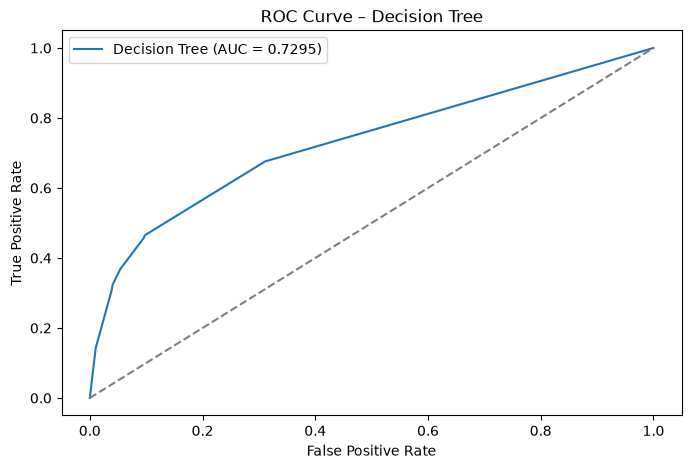

ROC AUC: 0.729478262706555


In [105]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds_roc = roc_curve(y_test, probabilities_test)
auc = roc_auc_score(y_test, probabilities_test)

plt.figure(figsize = (8, 5))
plt.plot(fpr, tpr, label = f'Decision Tree (AUC = {auc:.4f})')
plt.plot([0, 1], [0, 1], '--', color = 'gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve – Decision Tree')
plt.legend()
plt.show()

print('ROC AUC:', auc)

In [106]:
final_model = {'model': best_tree, 'threshold': best_threshold, 'features': X_train.columns.tolist()}

joblib.dump(final_model, 'credit_default_model.joblib')

['credit_default_model.joblib']

In [107]:
def credit_decision(client):
    probability = best_tree.predict_proba(client[X_train.columns])[:, 1][0]
    decision = 'Nie przyznać karty' if probability >= best_threshold else 'Przyznać kartę'
    return decision, probability

clients = X_test.sample(n = 10, random_state = 42)

results = []

for index, client in clients.iterrows():
    decision, probability = credit_decision(client.to_frame().T)
    results.append({'ID klienta': df.loc[index, 'ID'], 'Decyzja': decision, 'Ryzyko niewypłacalności': f'{probability:.2%}'})

display(pd.DataFrame(results))

,ID klienta,Decyzja,Ryzyko niewypłacalności
0,20640,Przyznać kartę,11.58%
1,7661,Nie przyznać karty,68.34%
2,13981,Przyznać kartę,21.80%
3,7163,Nie przyznać karty,68.34%
4,24018,Przyznać kartę,21.80%
5,500,Przyznać kartę,11.58%
6,10859,Przyznać kartę,11.58%
7,6464,Przyznać kartę,11.58%
8,17409,Przyznać kartę,11.58%
9,4620,Przyznać kartę,11.58%
